# Bland Altman plot     

### Bibliotecas utilizadas

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

### Lendo a base

In [5]:
caminho = r'C:\Users\saulosgil\OneDrive\Documentos\functional_tests_blinding\data\data_blinding.xlsx'
df = pd.read_excel(caminho)

df.head()

,id,idade,estado_civil,sexo,raca,renda,baixa_visao,cego,comorbidades,medicamentos,peso_kg,estatura_cm,imc,tug_1,tug_2,ts_1,ts_2
0,5,19,Solteiro,Feminino,Branco,Até 1 salário mínimo,1,0,Pre diabete,Loratadina e clenil,55.0,158,22.031726,8.65,6.54,15,18
1,9,18,Solteiro,Feminino,Preto,Até 1 salário mínimo,1,0,Ansiedade,Nenhum,70.0,171,23.938990,6.09,5.51,11,13
2,10,62,Divorciado,Masculino,Branco,1 – 2 salários mínimos,1,0,Nenhuma comorbidade,Nenhum nenhuma,85.0,180,26.234568,7.89,9.77,14,15
3,11,42,Solteiro,Masculino,Preto,1 – 2 salários mínimos,1,0,Nenhuma comorbidade,Não,105.0,168,37.202381,12.80,8.75,12,15
4,17,42,Solteiro,Masculino,Preto,Até 1 salário mínimo,1,0,Nenhuma comorbidade,Não,75.0,165,27.548209,10.00,8.10,10,12


## **Time Up and Go**

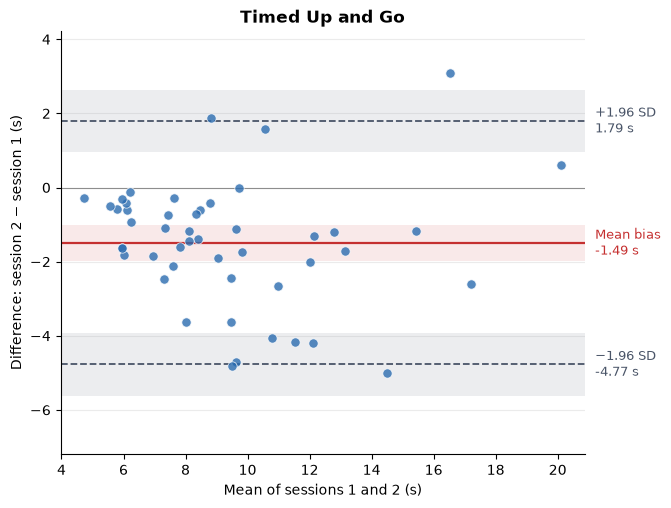

{'n': 48, 'bias': np.float64(-1.4904166666666667), 'bias_95ci': (np.float64(-1.9768752493650452), np.float64(-1.0039580839682882)), 'sd_diff': np.float64(1.6753074768065626), 'loa_lower': np.float64(-4.774019321207529), 'loa_upper': np.float64(1.7931859878741958), 'loa_lower_95ci': (np.float64(-5.616590302219067), np.float64(-3.931448340195991)), 'loa_upper_95ci': (np.float64(0.950615006862658), np.float64(2.6357569688857336)), 'prop_bias_slope': np.float64(-0.02923525396953219), 'prop_bias_p': np.float64(0.6947030702161762)}


In [6]:
def bland_altman_plot(data1, data2, groups=None, ax=None, units='s',
                      title='Bland-Altman plot', percent=False,
                      show_ci=True, show_regression=True):
    """
    data1, data2 : session 1 and session 2 (test and retest)
    groups       : optional, e.g. df['group'] (blind / low vision) to colour points
    percent      : if True, differences are expressed as % of the mean
                   (useful when heteroscedasticity is present)
    """
    # --- data (drop incomplete pairs) ---
    d = pd.DataFrame({'s1': np.asarray(data1, float), 's2': np.asarray(data2, float)})
    if groups is not None:
        d['g'] = np.asarray(groups)
    d = d.dropna()

    s1, s2 = d['s1'].to_numpy(), d['s2'].to_numpy()
    n = len(d)
    mean = (s1 + s2) / 2
    diff = s2 - s1                      # positive = slower at retest
    unit_diff = units
    if percent:
        diff = diff / mean * 100
        unit_diff = '%'

    # --- statistics ---
    md = diff.mean()
    sd = diff.std(ddof=1)               # sample SD
    lo, up = md - 1.96 * sd, md + 1.96 * sd
    tcrit = stats.t.ppf(0.975, n - 1)
    ci_md = tcrit * sd / np.sqrt(n)                 # 95% CI of the bias
    ci_loa = tcrit * np.sqrt(3 * sd**2 / n)         # 95% CI of the LoA (Bland & Altman, 1999)
    reg = stats.linregress(mean, diff)              # proportional bias test

    # --- figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5.5))
        fig.subplots_adjust(right=0.78)

    # CI bands
    if show_ci:
        ax.axhspan(md - ci_md, md + ci_md, color='#c53030', alpha=0.10, lw=0)
        for v in (up, lo):
            ax.axhspan(v - ci_loa, v + ci_loa, color='#4a5568', alpha=0.10, lw=0)

    # reference lines
    ax.axhline(0, color='black', linewidth=0.8, alpha=0.4)
    ax.axhline(md, color='#c53030', linewidth=1.6)
    ax.axhline(up, color='#4a5568', linestyle='--', linewidth=1.3)
    ax.axhline(lo, color='#4a5568', linestyle='--', linewidth=1.3)

    # points
    pts = dict(s=45, alpha=0.8, edgecolor='white', linewidth=0.6, zorder=3)
    if groups is None:
        ax.scatter(mean, diff, color='#2b6cb0', **pts)
    else:
        tmp = d.assign(mean=mean, diff=diff)
        for g, sub in tmp.groupby('g'):
            ax.scatter(sub['mean'], sub['diff'], label=str(g), **pts)

    # regression line (proportional bias)
    if show_regression:
        xs = np.linspace(mean.min(), mean.max(), 100)
        ax.plot(xs, reg.intercept + reg.slope * xs, color='#dd6b20',
                linestyle=':', linewidth=1.4,
                label=f'Proportional bias (slope p = {reg.pvalue:.3f})')

    # labels to the right of the lines
    trans = ax.get_yaxis_transform()
    def line_label(y, txt, colour):
        ax.text(1.02, y, txt, transform=trans, va='center', ha='left',
                fontsize=9.5, color=colour)
    line_label(up, f'+1.96 SD\n{up:.2f} {unit_diff}', '#4a5568')
    line_label(md, f'Mean bias\n{md:.2f} {unit_diff}', '#c53030')
    line_label(lo, f'−1.96 SD\n{lo:.2f} {unit_diff}', '#4a5568')

    # symmetric y-axis around the bias, with margin
    span = max(up + ci_loa - md, md - (lo - ci_loa), np.abs(diff - md).max())
    ax.set_ylim(md - 1.25 * span, md + 1.25 * span)

    ax.set_xlabel(f'Mean of sessions 1 and 2 ({units})')
    ax.set_ylabel(f'Difference: session 2 − session 1 ({unit_diff})')
    ax.set_title(title, loc='center', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.25)
    if groups is not None or show_regression:
        ax.legend(frameon=False, loc='upper left', fontsize=9)

    return {
        'n': n,
        'bias': md,
        'bias_95ci': (md - ci_md, md + ci_md),
        'sd_diff': sd,
        'loa_lower': lo,
        'loa_upper': up,
        'loa_lower_95ci': (lo - ci_loa, lo + ci_loa),
        'loa_upper_95ci': (up - ci_loa, up + ci_loa),
        'prop_bias_slope': reg.slope,
        'prop_bias_p': reg.pvalue,
    }


# --- usage ---
res = bland_altman_plot(df['tug_1'], df['tug_2'], units='s',
                        title='Timed Up and Go',
                        show_regression=False)

# saving at journal resolution:
plt.savefig('../figures/bland_altman_tug.png', dpi=600, bbox_inches='tight')

plt.show()
print(res)

# colouring by group (if the column exists):
# res = bland_altman_plot(df['tug_1'], df['tug_2'], groups=df['group'],
#                         title='Timed Up and Go — test-retest')


## **Timed stands**

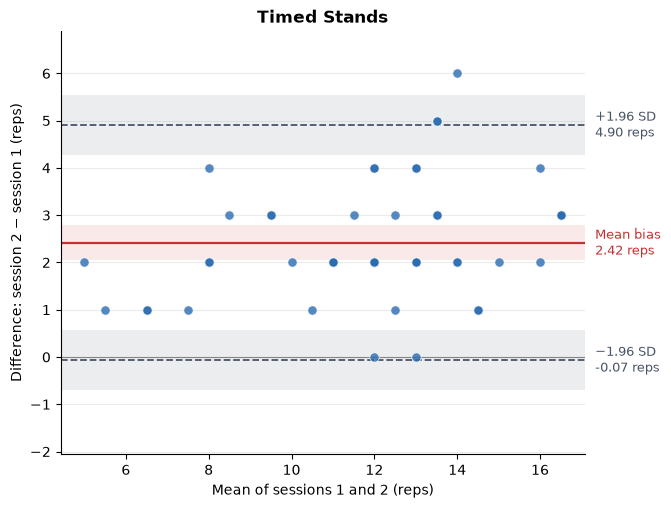

{'n': 48, 'bias': np.float64(2.4166666666666665), 'bias_95ci': (np.float64(2.0482368960546355), np.float64(2.7850964372786975)), 'sd_diff': np.float64(1.2688298065596444), 'loa_lower': np.float64(-0.07023975419023643), 'loa_upper': np.float64(4.9035730875235695), 'loa_lower_95ci': (np.float64(-0.7083788359112209), np.float64(0.567899327530748)), 'loa_upper_95ci': (np.float64(4.265434005802585), np.float64(5.541712169244554)), 'prop_bias_slope': np.float64(0.1241843822353189), 'prop_bias_p': np.float64(0.050383485862209705)}


In [7]:
def bland_altman_plot(data1, data2, groups=None, ax=None, units='s',
                      title='Bland-Altman plot', percent=False,
                      show_ci=True, show_regression=True):
    """
    data1, data2 : session 1 and session 2 (test and retest)
    groups       : optional, e.g. df['group'] (blind / low vision) to colour points
    percent      : if True, differences are expressed as % of the mean
                   (useful when heteroscedasticity is present)
    """
    # --- data (drop incomplete pairs) ---
    d = pd.DataFrame({'s1': np.asarray(data1, float), 's2': np.asarray(data2, float)})
    if groups is not None:
        d['g'] = np.asarray(groups)
    d = d.dropna()

    s1, s2 = d['s1'].to_numpy(), d['s2'].to_numpy()
    n = len(d)
    mean = (s1 + s2) / 2
    diff = s2 - s1                      # positive = slower at retest
    unit_diff = units
    if percent:
        diff = diff / mean * 100
        unit_diff = '%'

    # --- statistics ---
    md = diff.mean()
    sd = diff.std(ddof=1)               # sample SD
    lo, up = md - 1.96 * sd, md + 1.96 * sd
    tcrit = stats.t.ppf(0.975, n - 1)
    ci_md = tcrit * sd / np.sqrt(n)                 # 95% CI of the bias
    ci_loa = tcrit * np.sqrt(3 * sd**2 / n)         # 95% CI of the LoA (Bland & Altman, 1999)
    reg = stats.linregress(mean, diff)              # proportional bias test

    # --- figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5.5))
        fig.subplots_adjust(right=0.78)

    # CI bands
    if show_ci:
        ax.axhspan(md - ci_md, md + ci_md, color='#c53030', alpha=0.10, lw=0)
        for v in (up, lo):
            ax.axhspan(v - ci_loa, v + ci_loa, color='#4a5568', alpha=0.10, lw=0)

    # reference lines
    ax.axhline(0, color='black', linewidth=0.8, alpha=0.4)
    ax.axhline(md, color='#c53030', linewidth=1.6)
    ax.axhline(up, color='#4a5568', linestyle='--', linewidth=1.3)
    ax.axhline(lo, color='#4a5568', linestyle='--', linewidth=1.3)

    # points
    pts = dict(s=45, alpha=0.8, edgecolor='white', linewidth=0.6, zorder=3)
    if groups is None:
        ax.scatter(mean, diff, color='#2b6cb0', **pts)
    else:
        tmp = d.assign(mean=mean, diff=diff)
        for g, sub in tmp.groupby('g'):
            ax.scatter(sub['mean'], sub['diff'], label=str(g), **pts)

    # regression line (proportional bias)
    if show_regression:
        xs = np.linspace(mean.min(), mean.max(), 100)
        ax.plot(xs, reg.intercept + reg.slope * xs, color='#dd6b20',
                linestyle=':', linewidth=1.4,
                label=f'Proportional bias (slope p = {reg.pvalue:.3f})')

    # labels to the right of the lines
    trans = ax.get_yaxis_transform()
    def line_label(y, txt, colour):
        ax.text(1.02, y, txt, transform=trans, va='center', ha='left',
                fontsize=9.5, color=colour)
    line_label(up, f'+1.96 SD\n{up:.2f} {unit_diff}', '#4a5568')
    line_label(md, f'Mean bias\n{md:.2f} {unit_diff}', '#c53030')
    line_label(lo, f'−1.96 SD\n{lo:.2f} {unit_diff}', '#4a5568')

    # symmetric y-axis around the bias, with margin
    span = max(up + ci_loa - md, md - (lo - ci_loa), np.abs(diff - md).max())
    ax.set_ylim(md - 1.25 * span, md + 1.25 * span)

    ax.set_xlabel(f'Mean of sessions 1 and 2 ({units})')
    ax.set_ylabel(f'Difference: session 2 − session 1 ({unit_diff})')
    ax.set_title(title, loc='center', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.25)
    if groups is not None or show_regression:
        ax.legend(frameon=False, loc='upper left', fontsize=9)

    return {
        'n': n,
        'bias': md,
        'bias_95ci': (md - ci_md, md + ci_md),
        'sd_diff': sd,
        'loa_lower': lo,
        'loa_upper': up,
        'loa_lower_95ci': (lo - ci_loa, lo + ci_loa),
        'loa_upper_95ci': (up - ci_loa, up + ci_loa),
        'prop_bias_slope': reg.slope,
        'prop_bias_p': reg.pvalue,
    }


# --- usage ---
res = bland_altman_plot(df['ts_1'], df['ts_2'], units='reps',
                        title='Timed Stands',
                        show_regression=False)

# saving at journal resolution:
plt.savefig('../figures/bland_altman_ts.tiff', dpi=600, bbox_inches='tight')

plt.show()
print(res)

# colouring by group (if the column exists):
# res = bland_altman_plot(df['tug_1'], df['tug_2'], groups=df['group'],
#                         title='Timed Up and Go — test-retest')
